In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime
from datetime import date, time

#Install Yahoo Finance Libraries
try:
    import yfinance
except:
    !pip install -q yfinance
    import yfinance
    
try:
    import yahoofinancials
except:
    !pip install -q yahoofinancials
    import yahoofinancials
    
import yfinance as yf
from yahoofinancials import YahooFinancials

import warnings
warnings.filterwarnings('ignore')

#Download Historical Data
startdate='2010-01-01'
enddate=date.today()
dfData:pd.DataFrame = yf.download('AAPL', start=startdate, end=enddate, progress=False)


In [6]:
display(dfData.head())
#Remove Ticker row from Column Name
dfData = dfData.droplevel(1, axis=1)

# Rename the columns using the dictionary
rename_dict = {'Close': 'close', 'Volume': 'volume', 'High':'high', 'Open':'open', 'Low':'low'}
dfData.rename(columns=rename_dict, inplace=True)

Price                     Adj Close     Close      High       Low      Open  \
Ticker                         AAPL      AAPL      AAPL      AAPL      AAPL   
Date                                                                          
2010-01-04 00:00:00+00:00  6.454506  7.643214  7.660714  7.585000  7.622500   
2010-01-05 00:00:00+00:00  6.465664  7.656429  7.699643  7.616071  7.664286   
2010-01-06 00:00:00+00:00  6.362821  7.534643  7.686786  7.526786  7.656429   
2010-01-07 00:00:00+00:00  6.351057  7.520714  7.571429  7.466071  7.562500   
2010-01-08 00:00:00+00:00  6.393281  7.570714  7.571429  7.466429  7.510714   

Price                         Volume  
Ticker                          AAPL  
Date                                  
2010-01-04 00:00:00+00:00  493729600  
2010-01-05 00:00:00+00:00  601904800  
2010-01-06 00:00:00+00:00  552160000  
2010-01-07 00:00:00+00:00  477131200  
2010-01-08 00:00:00+00:00  447610800  


Price                      Adj Close     close      high       low      open  \
Date                                                                           
2010-01-04 00:00:00+00:00   6.454506  7.643214  7.660714  7.585000  7.622500   
2010-01-05 00:00:00+00:00   6.465664  7.656429  7.699643  7.616071  7.664286   
2010-01-06 00:00:00+00:00   6.362821  7.534643  7.686786  7.526786  7.656429   
2010-01-07 00:00:00+00:00   6.351057  7.520714  7.571429  7.466071  7.562500   
2010-01-08 00:00:00+00:00   6.393281  7.570714  7.571429  7.466429  7.510714   

Price                         volume  
Date                                  
2010-01-04 00:00:00+00:00  493729600  
2010-01-05 00:00:00+00:00  601904800  
2010-01-06 00:00:00+00:00  552160000  
2010-01-07 00:00:00+00:00  477131200  
2010-01-08 00:00:00+00:00  447610800  


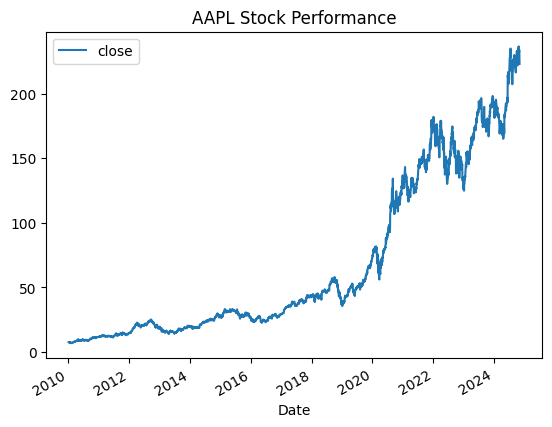

In [7]:
#Chart the Stock Performance
display(dfData.head())
dfData.plot(y='close', title='AAPL Stock Performance')
plt.show()

In [8]:
#Create Technical Analysis Indicators and Plot 
import pandas_ta as ta

# Calculate RSI
dfData['RSI-2'] = ta.rsi(dfData['close'], length=2)
dfData['RSI-7'] = ta.rsi(dfData['close'], length=7)
dfData['RSI-14'] = ta.rsi(dfData['close'], length=14)
#View Data so far
display(dfData.tail())

# Calculate CCI
dfData['CCI-30'] = ta.cci(close=dfData['close'], length=30, high=dfData['high'], low=dfData['low'])
dfData['CCI-50'] = ta.cci(close=dfData['close'], length=50, high=dfData['high'], low=dfData['low'])
dfData['CCI-100'] = ta.cci(close=dfData['close'], length=100, high=dfData['high'], low=dfData['low'])
#View Data so far
display(dfData.tail())

Price                       Adj Close       close        high         low  \
Date                                                                        
2024-10-28 00:00:00+00:00  233.399994  233.399994  234.729996  232.550003   
2024-10-29 00:00:00+00:00  233.669998  233.669998  234.330002  232.320007   
2024-10-30 00:00:00+00:00  230.100006  230.100006  233.470001  229.550003   
2024-10-31 00:00:00+00:00  225.910004  225.910004  229.830002  225.369995   
2024-11-01 00:00:00+00:00  222.910004  222.910004  225.350006  220.270004   

Price                            open    volume      RSI-2      RSI-7  \
Date                                                                    
2024-10-28 00:00:00+00:00  233.320007  36087100  77.421948  57.270412   
2024-10-29 00:00:00+00:00  233.100006  35417200  80.642404  58.244384   
2024-10-30 00:00:00+00:00  232.610001  47070900  16.899517  43.092590   
2024-10-31 00:00:00+00:00  229.339996  64370100   5.918373  31.774319   
2024-11-01 00:00:00+00

Price                       Adj Close       close        high         low  \
Date                                                                        
2024-10-28 00:00:00+00:00  233.399994  233.399994  234.729996  232.550003   
2024-10-29 00:00:00+00:00  233.669998  233.669998  234.330002  232.320007   
2024-10-30 00:00:00+00:00  230.100006  230.100006  233.470001  229.550003   
2024-10-31 00:00:00+00:00  225.910004  225.910004  229.830002  225.369995   
2024-11-01 00:00:00+00:00  222.910004  222.910004  225.350006  220.270004   

Price                            open    volume      RSI-2      RSI-7  \
Date                                                                    
2024-10-28 00:00:00+00:00  233.320007  36087100  77.421948  57.270412   
2024-10-29 00:00:00+00:00  233.100006  35417200  80.642404  58.244384   
2024-10-30 00:00:00+00:00  232.610001  47070900  16.899517  43.092590   
2024-10-31 00:00:00+00:00  229.339996  64370100   5.918373  31.774319   
2024-11-01 00:00:00+00

<Axes: xlabel='Date'>

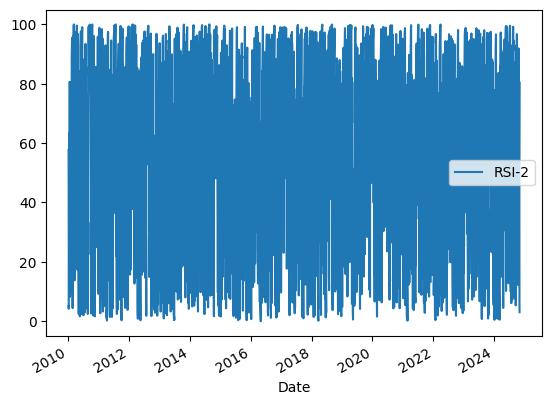

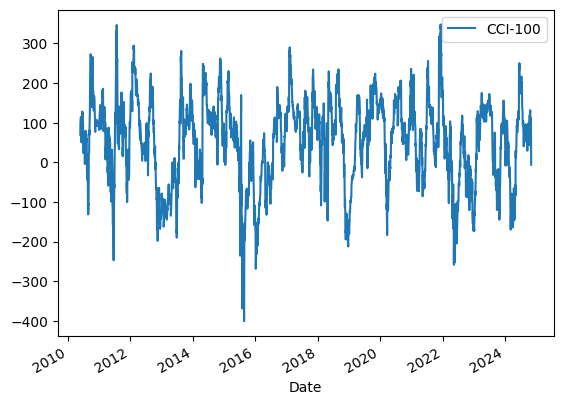

In [9]:
#Drop NaN Values
dfData.dropna()

#View Data so far
display(dfData.tail())

#Plot showing some Indicators above
dfData.plot(y='RSI-2')
dfData.plot(y='CCI-100')